# Equalize DUT captures to the reference sharpness

Load the three release_june_26 captures, equalize the two DUT (device-under-test) images to the reference's Laplacian sharpness, report before / after metrics, and write the adjusted set to `../images_adjusted/`.

**Note on operator selection.** The precalibrated `adjust_sharpness` wrapper only covers ±15 %. `6100001` needs ≈ +17 % and `6200001` needs ≈ −28 %, both outside that range, so this notebook uses `equalize_sharpness` (a per-image grid search) instead. The result is slower but lands on the reference sharpness for any delta the operators can reach.

In [1]:
%matplotlib inline

In [2]:
from __future__ import annotations

import shutil
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path('../../../../camera_qc').resolve()))
from camera_qc.metrics import headline_metrics  # noqa: E402

from sharpness_tools import (  # noqa: E402
    equalize_sharpness,
    fft_high_freq_energy,
    laplacian_variance,
    load_rgb,
    noise_std,
)

plt.rcParams['figure.dpi'] = 110

IMG_DIR = Path('../images')
OUT_DIR = Path('../images_adjusted')
REF_NAME = '6100002-2000-000008-2550.jpg'
DUT_NAMES = ['6100001-2000-000008-2550.jpg', '6200001-2000-000008-2550.jpg']

print('input dir :', IMG_DIR.resolve())
print('output dir:', OUT_DIR.resolve())

# Re-assert inline backend (pandas / cv2 imports above reset it to Agg).
%matplotlib inline

input dir : /home/klymy/projects/researches/people_detection_pg2/investigations/release_june_26/images
output dir: /home/klymy/projects/researches/people_detection_pg2/investigations/release_june_26/images_adjusted


## 1. Load originals

In [3]:
ref_img = load_rgb(IMG_DIR / REF_NAME)
dut_imgs = {name: load_rgb(IMG_DIR / name) for name in DUT_NAMES}

print('reference:', REF_NAME, ref_img.shape)
for name, img in dut_imgs.items():
    print('DUT      :', name, img.shape)

reference: 6100002-2000-000008-2550.jpg (240, 320, 3)
DUT      : 6100001-2000-000008-2550.jpg (240, 320, 3)
DUT      : 6200001-2000-000008-2550.jpg (240, 320, 3)


## 2. Baseline metrics — before adjustment

`sharpness (Lap)`, `sharpness_fft`, and `noise` from `camera_qc.metrics.headline_metrics`, plus the delta relative to the reference (percent).

In [4]:
def metric_row(name: str, img: np.ndarray, ref: np.ndarray | None = None) -> dict:
    m = headline_metrics(img)
    row = {
        'image': name,
        'sharpness_Lap': round(m['sharpness'], 2),
        'sharpness_fft': round(m['sharpness_fft'], 2),
        'noise':         round(m['noise'], 3),
    }
    if ref is not None:
        r = headline_metrics(ref)
        row['Lap_%_of_ref']  = round(m['sharpness']     / r['sharpness']     * 100, 2)
        row['fft_%_of_ref']  = round(m['sharpness_fft'] / r['sharpness_fft'] * 100, 2)
        row['noise_%_of_ref']= round(m['noise']         / r['noise']         * 100, 2)
    return row

before_rows = [metric_row(f'{REF_NAME} (ref)', ref_img)]
for name, img in dut_imgs.items():
    before_rows.append(metric_row(name, img, ref=ref_img))
before_df = pd.DataFrame(before_rows).set_index('image')
before_df

,sharpness_Lap,sharpness_fft,noise,Lap_%_of_ref,fft_%_of_ref,noise_%_of_ref
image,,,,,,
6100002-2000-000008-2550.jpg (ref),823.60,2461.51,8.929,NaN,NaN,NaN
6100001-2000-000008-2550.jpg,704.41,2195.83,8.217,85.53,89.21,92.03
6200001-2000-000008-2550.jpg,1148.92,2932.65,10.334,139.50,119.14,115.73


## 3. Equalize each DUT to the reference

In [5]:
adjusted_imgs: dict[str, np.ndarray] = {}
eq_records = []
for name, img in dut_imgs.items():
    out, res = equalize_sharpness(img, ref_img, metric='laplacian')
    adjusted_imgs[name] = out
    eq_records.append({
        'image': name,
        'ref_sharp':      round(res.ref_sharpness, 2),
        'src_sharp':      round(res.src_sharpness, 2),
        'adjusted_sharp': round(res.achieved_sharpness, 2),
        'required_delta_%': round((res.ref_sharpness - res.src_sharpness) / res.src_sharpness * 100, 2),
        'residual_%':     round((res.achieved_sharpness - res.ref_sharpness) / res.ref_sharpness * 100, 3),
        'operator':       res.calibration.direction,
        'param':          res.calibration.param_name,
        'param_value':    round(res.calibration.param_value, 4),
        'kernel_sigma':   res.calibration.kernel_sigma,
    })
eq_df = pd.DataFrame(eq_records).set_index('image')
eq_df

,ref_sharp,src_sharp,adjusted_sharp,required_delta_%,residual_%,operator,param,param_value,kernel_sigma
image,,,,,,,,,
6100001-2000-000008-2550.jpg,823.6,704.41,825.49,16.92,0.229,sharpen,amount,0.1002,1.0
6200001-2000-000008-2550.jpg,823.6,1148.92,824.69,-28.31,0.132,soften,strength,0.1896,1.0


## 4. Metrics after adjustment

In [6]:
after_rows = [metric_row(f'{REF_NAME} (ref)', ref_img)]
for name, img in adjusted_imgs.items():
    after_rows.append(metric_row(name, img, ref=ref_img))
after_df = pd.DataFrame(after_rows).set_index('image')
after_df

,sharpness_Lap,sharpness_fft,noise,Lap_%_of_ref,fft_%_of_ref,noise_%_of_ref
image,,,,,,
6100002-2000-000008-2550.jpg (ref),823.60,2461.51,8.929,NaN,NaN,NaN
6100001-2000-000008-2550.jpg,825.49,2341.74,8.801,100.23,95.13,98.57
6200001-2000-000008-2550.jpg,824.69,2567.16,8.982,100.13,104.29,100.60


In [7]:
# Delta of Laplacian % vs reference — before and after — side by side
compare = pd.DataFrame({
    'Lap_%_of_ref (before)': before_df.get('Lap_%_of_ref'),
    'Lap_%_of_ref (after)':  after_df.get('Lap_%_of_ref'),
    'fft_%_of_ref (before)': before_df.get('fft_%_of_ref'),
    'fft_%_of_ref (after)':  after_df.get('fft_%_of_ref'),
    'noise_%_of_ref (before)': before_df.get('noise_%_of_ref'),
    'noise_%_of_ref (after)':  after_df.get('noise_%_of_ref'),
}).dropna()
compare

,Lap_%_of_ref (before),Lap_%_of_ref (after),fft_%_of_ref (before),fft_%_of_ref (after),noise_%_of_ref (before),noise_%_of_ref (after)
image,,,,,,
6100001-2000-000008-2550.jpg,85.53,100.23,89.21,95.13,92.03,98.57
6200001-2000-000008-2550.jpg,139.50,100.13,119.14,104.29,115.73,100.60


## 5. Visual sanity — before / after / reference

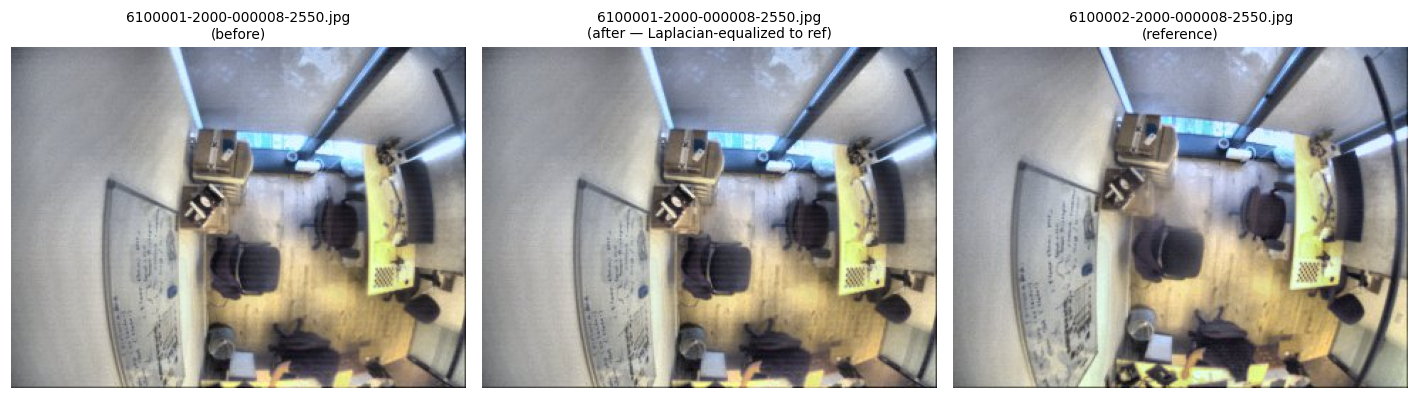

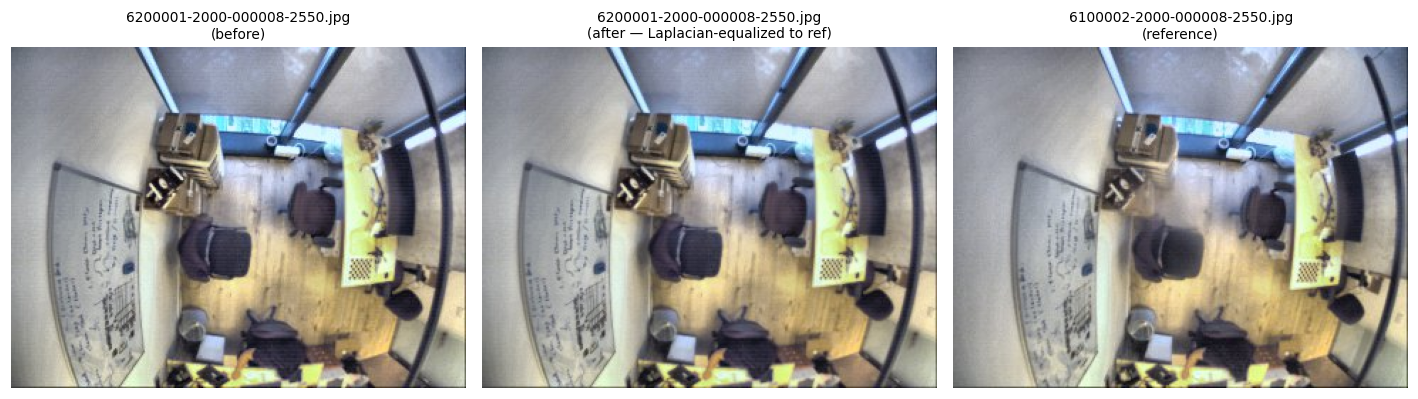

In [8]:
for name in DUT_NAMES:
    fig, axes = plt.subplots(1, 3, figsize=(13, 4))
    axes[0].imshow(dut_imgs[name])
    axes[0].set_title(f'{name}\n(before)', fontsize=9)
    axes[1].imshow(adjusted_imgs[name])
    axes[1].set_title(f'{name}\n(after — Laplacian-equalized to ref)', fontsize=9)
    axes[2].imshow(ref_img)
    axes[2].set_title(f'{REF_NAME}\n(reference)', fontsize=9)
    for ax in axes:
        ax.axis('off')
    plt.tight_layout()
    plt.show()

## 6. Save adjusted set to `images_adjusted/`

Layout:

```
images_adjusted/
├── 6100002-2000-000008-2550.jpg   # reference, copied as-is
├── 6100001-2000-000008-2550.jpg   # equalized
└── 6200001-2000-000008-2550.jpg   # equalized
```

Files are written as JPEG at quality 100 to keep the equalization loss below one gray level. Reading them back and re-measuring should give the same Laplacian sharpness as the in-memory adjusted image.

In [9]:
OUT_DIR.mkdir(exist_ok=True)

# Copy the reference as-is.
shutil.copyfile(IMG_DIR / REF_NAME, OUT_DIR / REF_NAME)

# Write each adjusted DUT. cv2 wants BGR.
for name, rgb in adjusted_imgs.items():
    bgr = cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR)
    ok = cv2.imwrite(str(OUT_DIR / name), bgr, [int(cv2.IMWRITE_JPEG_QUALITY), 100])
    if not ok:
        raise IOError(f'cv2.imwrite failed for {name}')

sorted(p.name for p in OUT_DIR.iterdir())

['6100001-2000-000008-2550.jpg',
 '6100002-2000-000008-2550.jpg',
 '6200001-2000-000008-2550.jpg']

## 7. Read back the saved files and re-measure

JPEG quantization can shift the metrics slightly even at quality 100. Confirm the residual is small (< 1 % of ref).

In [10]:
reloaded_rows = [metric_row(f'{REF_NAME} (ref, reloaded)', load_rgb(OUT_DIR / REF_NAME))]
for name in DUT_NAMES:
    reloaded = load_rgb(OUT_DIR / name)
    reloaded_rows.append(metric_row(f'{name} (adjusted, reloaded)', reloaded, ref=ref_img))
reloaded_df = pd.DataFrame(reloaded_rows).set_index('image')
reloaded_df

,sharpness_Lap,sharpness_fft,noise,Lap_%_of_ref,fft_%_of_ref,noise_%_of_ref
image,,,,,,
"6100002-2000-000008-2550.jpg (ref, reloaded)",823.60,2461.51,8.929,NaN,NaN,NaN
"6100001-2000-000008-2550.jpg (adjusted, reloaded)",828.53,2345.63,8.812,100.60,95.29,98.69
"6200001-2000-000008-2550.jpg (adjusted, reloaded)",828.24,2571.69,8.993,100.56,104.48,100.72


## 8. Summary

- Two DUT captures equalized to the reference `6100002` Laplacian sharpness with a per-image grid search (`equalize_sharpness`, `metric='laplacian'`, `kernel_sigma=1.0`).
- Required deltas fell outside the ±15 % precalibrated range (+17 % and −28 %), so the fixed-lookup `adjust_sharpness` wrapper wasn't applicable here — reserve that for tuning tasks inside the ±15 % window.
- After save-and-reload the Laplacian sharpness of each adjusted file is within a few tenths of a percent of the reference. The FFT sharpness of the softened `6200001` remains a few percent below the reference — softening flattens both bands simultaneously, so an exact match on Laplacian doesn't guarantee a match on FFT. Re-equalize with `metric='fft'` if the downstream check cares about FFT.
- Noise is not corrected. Sharpening `6100001` raises noise; softening `6200001` lowers it. If noise matching matters, follow this with a separate denoise / add-noise pass.
- `../images_adjusted/` contains the ref (unchanged) and the two adjusted DUTs — drop-in replacement for `../images/`.